In [9]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer

csv_name = "Annotated_Corpus.csv"
search_dir = os.path.abspath(os.getcwd())
CSV_PATH = None

while True:
	candidate = os.path.join(search_dir, "dataset", csv_name)
	if os.path.isfile(candidate):
		CSV_PATH = candidate
		break

	parent_dir = os.path.dirname(search_dir)
	if parent_dir == search_dir:
		break
	search_dir = parent_dir

if CSV_PATH is None:
	raise FileNotFoundError(
		f"Could not find dataset/{csv_name} starting from {os.getcwd()}. "
		"Check the dataset location and update CSV_PATH."
	)

OUTPUT_DIR = "./clustering_output"
EMBEDDING_MODEL = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"

RANDOM_SEED = 42
MIN_K = 2
MAX_K = 8
BATCH_SIZE = 16

os.makedirs(OUTPUT_DIR, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cpu


In [10]:
df = pd.read_csv(CSV_PATH, dtype=str, keep_default_na=False)

required = {"note_id", "token"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

df["note_id"] = df["note_id"].str.strip()
df["token"] = df["token"].str.strip()
df = df[(df["note_id"] != "") & (df["token"] != "")].copy()

notes_df = (
    df.groupby("note_id", sort=False)["token"]
      .apply(lambda x: " ".join(x))
      .reset_index(name="text")
)
notes_df["text"] = notes_df["text"].str.strip()
notes_df = notes_df[notes_df["text"] != ""].reset_index(drop=True)

print("Token rows:", len(df))
print("Clinical notes:", len(notes_df))
display(notes_df.head())

if len(notes_df) < 3:
    raise ValueError("At least 3 clinical notes are required.")

Token rows: 10743
Clinical notes: 534


,note_id,text
0,syn001,রোগীর গত তিন দিন ধরে জ্বর রয়েছে এবং বুক অস্বস...
1,syn002,রোগীর ডায়াবেটিস ধরা পড়েছে । বর্তমানে মেটফরমি...
2,syn003,পরীক্ষা হিসেবে রক্ত পরীক্ষা করা হয়েছে এবং ফল ...
3,syn004,রোগী বুক ব্যথা নেই বলেছেন । সমস্যাটি গত তিন দি...
4,syn005,"রোগীর জ্বর কমেছে , তবে গত তিন দিন ধরে পুনরায় ..."


count    534.000000
mean      20.117978
std       12.777470
min        6.000000
25%       12.000000
50%       16.000000
75%       24.000000
max       87.000000
Name: word_count, dtype: float64

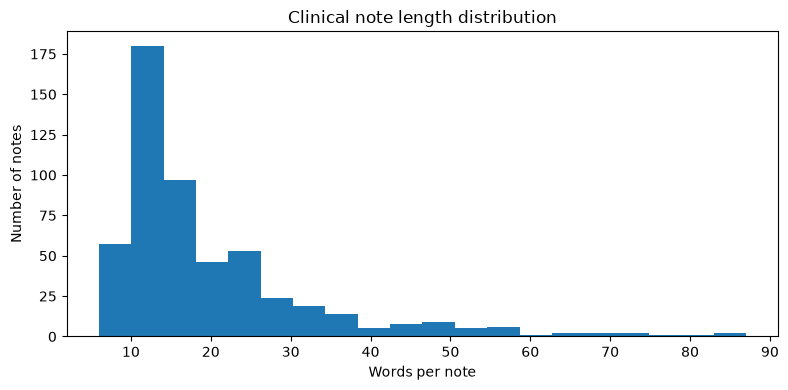

In [11]:
notes_df["word_count"] = notes_df["text"].str.split().str.len()
display(notes_df["word_count"].describe())

plt.figure(figsize=(8, 4))
plt.hist(notes_df["word_count"], bins=20)
plt.xlabel("Words per note")
plt.ylabel("Number of notes")
plt.title("Clinical note length distribution")
plt.tight_layout()
plt.show()

In [12]:
embedding_model = SentenceTransformer(EMBEDDING_MODEL, device=DEVICE)

embeddings = embedding_model.encode(
    notes_df["text"].tolist(),
    batch_size=BATCH_SIZE,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True,
)

print("Embedding shape:", embeddings.shape)

d:\Users\DEBJIT DAS\MedBhasha-Resources\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\DEBJIT   DAS\.cache\huggingface\hub\models--sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
d:\Users\DEBJIT DAS\MedBhasha-Resources\.venv\Lib\site-p

Embedding shape: (534, 384)


,k,silhouette
0,2,0.508460
1,3,0.213281
2,4,0.225289
3,5,0.239343
4,6,0.253066
5,7,0.219641
6,8,0.213662


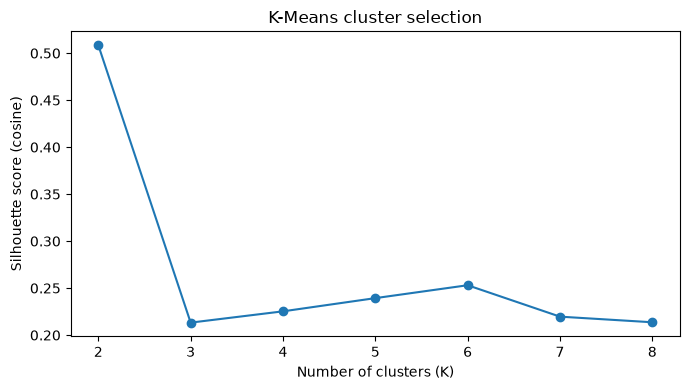

In [13]:
max_k = min(MAX_K, len(notes_df) - 1)
k_values = list(range(MIN_K, max_k + 1))
if not k_values:
    raise ValueError("Not enough notes for the selected K range.")

scores = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=10)
    labels = model.fit_predict(embeddings)
    score = silhouette_score(embeddings, labels, metric="cosine")
    scores.append({"k": k, "silhouette": score})

silhouette_df = pd.DataFrame(scores)
display(silhouette_df)

plt.figure(figsize=(7, 4))
plt.plot(silhouette_df["k"], silhouette_df["silhouette"], marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score (cosine)")
plt.title("K-Means cluster selection")
plt.xticks(k_values)
plt.tight_layout()
plt.show()

In [15]:
best_k = int(silhouette_df.loc[silhouette_df["silhouette"].idxmax(), "k"])
cluster_model = KMeans(n_clusters=best_k, random_state=RANDOM_SEED, n_init=10)
notes_df["cluster"] = cluster_model.fit_predict(embeddings)

tfidf = TfidfVectorizer(
    token_pattern=r"(?u)\b\w+\b",
    max_features=3000,
    ngram_range=(1, 2),
)
tfidf_matrix = tfidf.fit_transform(notes_df["text"])
terms = np.array(tfidf.get_feature_names_out())

cluster_keywords = {}
for cluster_id in sorted(notes_df["cluster"].unique()):
    idx = np.where(notes_df["cluster"].to_numpy() == cluster_id)[0]
    mean_scores = np.asarray(tfidf_matrix[idx].mean(axis=0)).ravel()
    top_idx = mean_scores.argsort()[::-1][:10]
    cluster_keywords[int(cluster_id)] = terms[top_idx].tolist()

for cluster_id, keywords in cluster_keywords.items():
    print(f"Cluster {cluster_id}: {', '.join(keywords)}")

Cluster 0: র, ন, ছ, গ, ক, ব, ত, য, হয, হয ছ
Cluster 1: র, ন, ক, ব, স, ত, য, আম, প, ছ


In [16]:
for cluster_id in sorted(notes_df["cluster"].unique()):
    subset = notes_df[notes_df["cluster"] == cluster_id]
    print("\n" + "=" * 70)
    print(f"CLUSTER {cluster_id} — {len(subset)} notes")
    print("Keywords:", ", ".join(cluster_keywords[int(cluster_id)]))
    print("-" * 70)
    for _, row in subset.head(10).iterrows():
        print(f"Note ID: {row['note_id']}")
        print(row["text"][:600])
        print()


CLUSTER 0 — 339 notes
Keywords: র, ন, ছ, গ, ক, ব, ত, য, হয, হয ছ
----------------------------------------------------------------------
Note ID: syn001
রোগীর গত তিন দিন ধরে জ্বর রয়েছে এবং বুক অস্বস্তি হচ্ছে ।

Note ID: syn003
পরীক্ষা হিসেবে রক্ত পরীক্ষা করা হয়েছে এবং ফল ১৪০ / ৯০ দেখানো হয়েছে ।

Note ID: syn004
রোগী বুক ব্যথা নেই বলেছেন । সমস্যাটি গত তিন দিন ধরে শুরু হয়েছে ।

Note ID: syn005
রোগীর জ্বর কমেছে , তবে গত তিন দিন ধরে পুনরায় দেখা দিতে পারে বলে জানিয়েছেন ।

Note ID: syn006
রোগীর ডায়াবেটিস আছে কি না তা নিশ্চিত নয় ; অতিরিক্ত রক্ত পরীক্ষা করার কথা বলা হয়েছে ।

Note ID: syn007
রোগীকে মেটফরমিন ৫০০ মিগ্রা দেওয়া হয়েছে এবং রক্ত পরীক্ষা করতে বলা হয়েছে ।

Note ID: syn008
রিপোর্টে রক্ত পরীক্ষা এর ফল ১৪০ / ৯০ লেখা আছে । বুক এ কোনো অস্বস্তি নেই ।

Note ID: syn009
রোগীর জ্বর এবং দুর্বলতা এর সঙ্গে বুক এ ব্যথা আছে ।

Note ID: syn011
রোগী গত তিন দিন ধরে জ্বর অনুভব করেছেন । তিনি ডায়াবেটিস এর ইতিহাস উল্লেখ করেছেন ।

Note ID: syn012
পর্যবেক্ষণে বুক সংক্রান্ত সমস্যা ও জ্বর লক্ষ্য করা

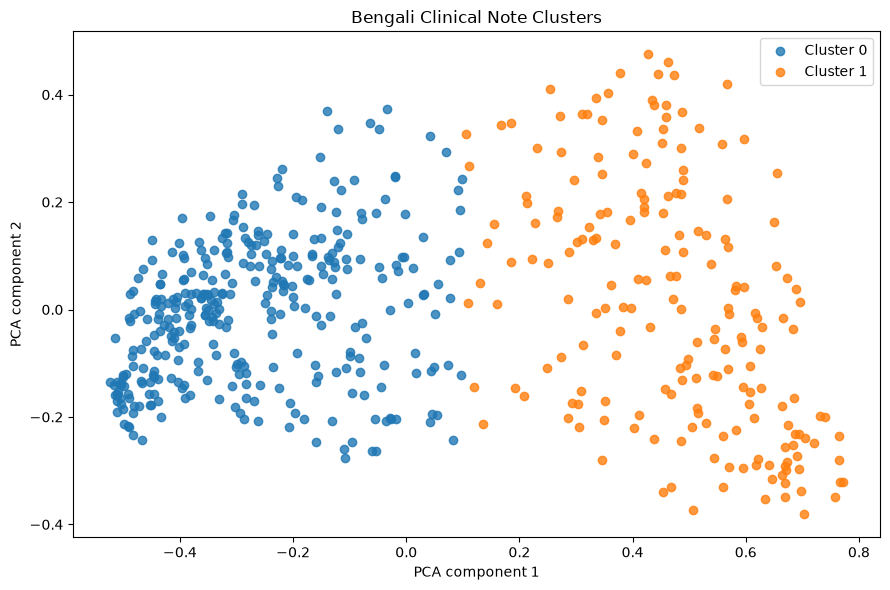

In [17]:
pca = PCA(n_components=2, random_state=RANDOM_SEED)
coords = pca.fit_transform(embeddings)

plot_df = notes_df[["note_id", "cluster"]].copy()
plot_df["x"] = coords[:, 0]
plot_df["y"] = coords[:, 1]

plt.figure(figsize=(9, 6))
for cluster_id in sorted(plot_df["cluster"].unique()):
    part = plot_df[plot_df["cluster"] == cluster_id]
    plt.scatter(part["x"], part["y"], label=f"Cluster {cluster_id}", alpha=0.8)

plt.xlabel("PCA component 1")
plt.ylabel("PCA component 2")
plt.title("Bengali Clinical Note Clusters")
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
assignments_path = os.path.join(OUTPUT_DIR, "clinical_note_clusters.csv")
notes_df.to_csv(assignments_path, index=False, encoding="utf-8-sig")

summary_rows = []
for cluster_id in sorted(notes_df["cluster"].unique()):
    subset = notes_df[notes_df["cluster"] == cluster_id]
    summary_rows.append({
        "cluster": int(cluster_id),
        "number_of_notes": int(len(subset)),
        "keywords": ", ".join(cluster_keywords[int(cluster_id)]),
        "example_note_ids": ", ".join(subset["note_id"].head(5).astype(str)),
    })

summary_df = pd.DataFrame(summary_rows)
summary_path = os.path.join(OUTPUT_DIR, "cluster_summary.csv")
summary_df.to_csv(summary_path, index=False, encoding="utf-8-sig")

print("Saved:", os.path.abspath(assignments_path))
print("Saved:", os.path.abspath(summary_path))
display(summary_df)

Saved: d:\Users\DEBJIT DAS\MedBhasha-Resources\clustering_output\clinical_note_clusters.csv
Saved: d:\Users\DEBJIT DAS\MedBhasha-Resources\clustering_output\cluster_summary.csv


,cluster,number_of_notes,keywords,example_note_ids
0,0,339,"র, ন, ছ, গ, ক, ব, ত, য, হয, হয ছ","syn001, syn003, syn004, syn005, syn006"
1,1,195,"র, ন, ক, ব, স, ত, য, আম, প, ছ","syn002, syn010, syn016, syn036, syn042"
